# Data Observation


I am at learning phase the code or data may be wrong

----for any suggestions or report please comment.



--------------- Thank you 😊

In [257]:
import numpy as np
import pandas as pd

**Data import**

In [258]:
data=pd.read_csv('/content/ai4i2020.csv')
data=pd.DataFrame(data)

In [259]:
data.head(5)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [260]:
data.head(5).to_csv('sample.csv',index=False)

In [261]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [262]:
data.nunique()

,0
UDI,10000
Product ID,10000
Type,3
Air temperature [K],93
Process temperature [K],82
Rotational speed [rpm],941
Torque [Nm],577
Tool wear [min],246
Machine failure,2
TWF,2


# Chart Vizulization

In [263]:
import matplotlib.pyplot as plt

In [264]:
data[['Torque [Nm]','Air temperature [K]','Process temperature [K]','Rotational speed [rpm]','Torque [Nm]','Tool wear [min]']].describe()

,Torque [Nm],Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,39.986910,300.004930,310.005560,1538.776100,39.986910,107.951000
std,9.968934,2.000259,1.483734,179.284096,9.968934,63.654147
min,3.800000,295.300000,305.700000,1168.000000,3.800000,0.000000
25%,33.200000,298.300000,308.800000,1423.000000,33.200000,53.000000
50%,40.100000,300.100000,310.100000,1503.000000,40.100000,108.000000
75%,46.800000,301.500000,311.100000,1612.000000,46.800000,162.000000
max,76.600000,304.500000,313.800000,2886.000000,76.600000,253.000000


In [265]:
data.groupby('Type')['Product ID'].count()

,Product ID
Type,
H,1003
L,6000
M,2997


In [266]:
Total_machine_failure=data['Machine failure'].sum()
print(f'Total Machine Failed:{Total_machine_failure} Times !')

Total Machine Failed:339 Times !


In [267]:
data.iloc[:,7:].head()

,Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,0,0,0,0,0,0,0
1,3,0,0,0,0,0,0
2,5,0,0,0,0,0,0
3,7,0,0,0,0,0,0
4,9,0,0,0,0,0,0


In [268]:
Specific_failure=data.columns[7:]

In [269]:
Catagory_wise_failure=data.groupby('Type')[Specific_failure].sum()
Catagory_wise_failure

,Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
Type,,,,,,,
H,107742,21,7,8,5,2,4
L,650273,235,25,76,59,87,13
M,321495,83,14,31,31,9,2


In [270]:
data.iloc[:,8:].sum()

,0
Machine failure,339
TWF,46
HDF,115
PWF,95
OSF,98
RNF,19


In [271]:
data['Tool wear [min]'].sum()

np.int64(1079510)

In [272]:
Total_wear_hours=data['Tool wear [min]'].sum()/60
Total_wear_days=Total_wear_hours/24
print(f'Total tool wear time:{Total_wear_hours.round(decimals=2)} Hours')
print(f'Total tool wear time:{Total_wear_days.round(decimals=2)} Days')

Total tool wear time:17991.83 Hours
Total tool wear time:749.66 Days


# Data Visualize

In [273]:
Specific_failure_1=data.columns[9:]
print(Specific_failure_1)

Index(['TWF', 'HDF', 'PWF', 'OSF', 'RNF'], dtype='object')


In [274]:
type_failure=data.groupby('Type')['Machine failure'].sum()
type_failure

,Machine failure
Type,
H,21
L,235
M,83


In [275]:
Type_Manufacture=data.groupby('Type')['UDI'].count()
Type_Manufacture

,UDI
Type,
H,1003
L,6000
M,2997


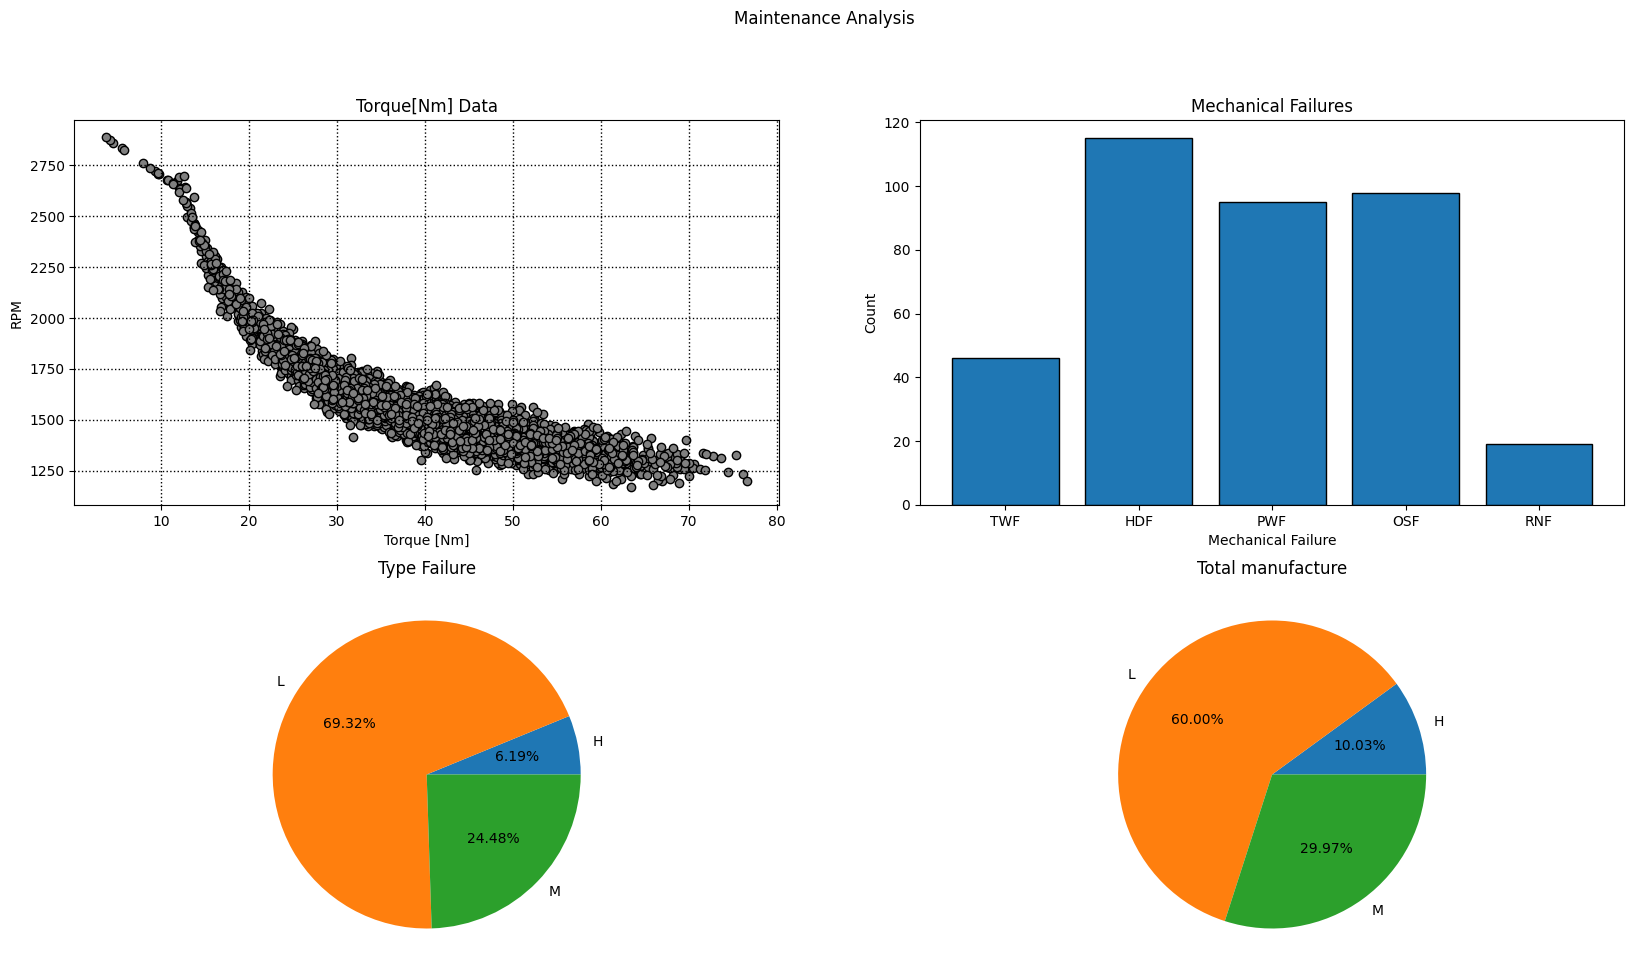

In [276]:
fig,ax=plt.subplots(2,2,figsize=(20,11))

plt.suptitle('Maintenance Analysis')

ax[0,0].scatter(data['Torque [Nm]'],data['Rotational speed [rpm]'],color="grey",edgecolor='black')
ax[0,0].grid(c='black',linestyle=':',linewidth=1)
ax[0,0].set_title('Torque[Nm] Data')
ax[0,0].set_xlabel('Torque [Nm]')
ax[0,0].set_ylabel('RPM')

ax[0,1].bar(Specific_failure_1,data.iloc[:,9:].sum(),edgecolor='black')
ax[0,1].set_xlabel('Mechanical Failure')
ax[0,1].set_ylabel('Count')
ax[0,1].set_title('Mechanical Failures')


ax[1,0].pie(type_failure,labels=type_failure.index,autopct='%1.2f%%')
ax[1,0].set_title('Type Failure')

ax[1,1].pie(Type_Manufacture,labels=Type_Manufacture.index,autopct='%1.2f%%')
ax[1,1].set_title('Total manufacture')


plt.show()

# Model

**Dataset Preparation**

In [277]:
from sklearn.model_selection import train_test_split

In [278]:
df=pd.get_dummies(data,columns=['Type'],drop_first=True)

In [279]:
x=df.iloc[:,3:6]

In [280]:
x.head(3)

,Process temperature [K],Rotational speed [rpm],Torque [Nm]
0,308.6,1551,42.8
1,308.7,1408,46.3
2,308.5,1498,49.4


In [281]:
y=df['Machine failure']

In [282]:
y[:3]

,Machine failure
0,0
1,0
2,0


In [283]:
len(x)

10000

In [284]:
len(y)

10000

In [285]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.2,random_state=32,stratify=y)

In [286]:
print(f'the len of x_train:{len(x_train)} & x_test{len(x_test)}')
print(f'the len of y_train:{len(y_train)} & y_test{len(y_test)}')

the len of x_train:8000 & x_test2000
the len of y_train:8000 & y_test2000


# Model Preparation

In [287]:
from sklearn.ensemble import RandomForestClassifier

In [300]:
model=RandomForestClassifier(class_weight={0:1,1:10},random_state=32)

In [301]:
model.fit(x_train,y_train)

RandomForestClassifier(class_weight={0: 1, 1: 10}, random_state=32)

# Model Prediction

In [302]:
from sklearn.metrics import classification_report

In [303]:
pred=model.predict(x_test)

In [304]:
print('-----Result-----')
print(classification_report(y_test,pred))

-----Result-----
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.87      0.29      0.44        68

    accuracy                           0.97      2000
   macro avg       0.92      0.65      0.71      2000
weighted avg       0.97      0.97      0.97      2000



# looks like the model is lazy beacuse data's Machine failure data is bias, we need to tweek it 😅

# Increasing alert from 0.5 to 0.3

In [305]:
probabilities = model.predict_proba(x_test)[:,1]

In [314]:
custom_threshold=0.20
tweek_prob=(probabilities>=custom_threshold).astype(int)

In [315]:
print('-----New tweek result------')
print(classification_report(y_test,tweek_prob))

-----New tweek result------
              precision    recall  f1-score   support

           0       0.98      0.96      0.97      1932
           1       0.30      0.43      0.35        68

    accuracy                           0.95      2000
   macro avg       0.64      0.70      0.66      2000
weighted avg       0.96      0.95      0.95      2000



---The Precession is inversely proptional with recall ---
if we increase recall value it
simultaneously decrease the precision or vice-versa

# Lets make The model function

In [321]:
def check_machine_failure(process_temp, rpm, torque,threshold=0.15):
  df=pd.DataFrame({
      'Process temperature [K]': [process_temp],
        'Rotational speed [rpm]': [rpm],
        'Torque [Nm]': [torque],
  })
  raw_prob=model.predict_proba(df)
  fn_prob=raw_prob[:,1][0]
  print(f'Probability of failure:{fn_prob *100:.2f}%')
  if fn_prob>=threshold :
    print("Warning: Machinehas potential falure Risk !")
    print('Request for immediate checkup')
  else:
    print('Machine probably safe')


In [322]:
check_machine_failure(309.1,7380,52.5)

Probability of failure:29.00%
Request for immediate checkup
